In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import matplotlib as mpl
plt.style.use("article.mplstyle")

import mne

from statannotations.Annotator import Annotator
import itertools

import glob
import os
import sys
from scipy.io import savemat, loadmat
from scipy.stats import pearsonr, spearmanr, sem
from statsmodels.stats.multitest import fdrcorrection
import statsmodels.formula.api as smf
import pingouin as pg
import scipy.stats as stats

from mne.stats import permutation_cluster_test, spatio_temporal_cluster_test, combine_adjacency
from mne.stats import permutation_cluster_1samp_test

sys.path.append('/Users/cindyzhang/Documents/Audiomotor_Piano/AM_EEG/utils')
mne.set_log_level('CRITICAL')
import warnings 
warnings.filterwarnings("ignore", category=FutureWarning)

from ERP_utils import *
from update_sub_lists import*
from plot_utils import *
from stats_utils import *

In [5]:
pwd()

'/Users/cindyzhang/Documents/Audiomotor_Piano/AM_EEG/ARTICLE_FIGS'

In [6]:
# np.random.seed(42)

#plotting parameters
firsts_color = 'teal'
others_color = 'coral'

axis_fontsize = 20
xtick_fontsize = 15

In [7]:
erp_times = create_erp_times(-0.5,0.5, 128)
ep_path = '../analysis_error/error_epochs_data_n05to05_30Hz_corrected'
mapchange_path = '../analysis_error/mapchange_csv_corrected_since'

#plotting parameters
ch_to_plot = 'Fz' #use Fz for main figs
ch_idx = ch_index([ch_to_plot])

## Prep data

In [8]:
# threshold_percentile = 75

In [9]:
def plot_ci95(distr, bar_ypos, bracketsize = 3, **kwargs):

    ci_l, ci_u = ci95_bs(distr, axis = 0)
    plt.hlines(bar_ypos, ci_l, ci_u, **kwargs)
    plt.vlines(ci_l, bar_ypos - bracketsize, bar_ypos + bracketsize, **kwargs)
    plt.vlines(ci_u, bar_ypos - bracketsize, bar_ypos + bracketsize, **kwargs)
    

def config_bs_plot(bar_ypos, fontsize = 20, **kwargs):
    #plot vertical line at 0
    plt.vlines(0, 0, bar_ypos, **kwargs)

    #plt.legend(fontsize = xtick_fontsize)
    plt.ylim(0, bar_ypos+10)
    plt.xlabel(r'Mean difference ($\mu$V)', fontsize = fontsize)
    plt.ylabel('Frequency', fontsize = fontsize)
    plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 1e6:.1f}'))
    plt.yticks([0, 120],fontsize = fontsize*0.7)
    plt.xticks(fontsize = fontsize*0.7)
    plt.xlim(-2.5e-6,1e-6)

# def permutation_test_compare(data1, data2, n_permutations = 10000):
#     """
#     Performs permutations test for 2 observed datasets
#     data1, data2: 1D numpy arrays 
#     n_permutations: number of permutations to perform
#     returns p-value of test

#     """
#     obs_diff = np.mean(data1) - np.mean(data2)
#     combined = np.concatenate([data1, data2])
#     n_1 = len(data1)
#     perm_diffs = np.zeros(n_permutations)

#     for i in range(n_permutations):
#         np.random.shuffle(combined)
#         perm_data1 = combined[:n_1]
#         perm_data2 = combined[n_1:]
#         perm_diffs[i] = np.mean(perm_data1) - np.mean(perm_data2)
#     p_2tail = np.mean(np.abs(perm_diffs) >= np.abs(obs_diff))
#     return p_2tail


def permutation_test_compare(data1, data2, n_permutations=10000):
    """
    Performs a two-sided permutation test comparing the means of two datasets.
    Returns an approximate p-value.
    """
    obs_diff = np.mean(data1) - np.mean(data2)
    combined = np.concatenate([data1, data2])
    n_1 = len(data1)
    perm_diffs = np.zeros(n_permutations)

    for i in range(n_permutations):
        permuted = np.random.permutation(combined)
        perm_data1 = permuted[:n_1]
        perm_data2 = permuted[n_1:]
        perm_diffs[i] = np.mean(perm_data1) - np.mean(perm_data2)

    p_2tail = np.mean(np.abs(perm_diffs) >= np.abs(obs_diff))
    return max(p_2tail, 1 / n_permutations)


In [10]:
def load_epochs_df(subjects_to_process, periods):

    eps_df_all = pd.DataFrame()

    for subject in subjects_to_process:
        for period in periods: 

            ep_file = os.path.join(ep_path, f'error_epochs_all_{period}_{subject}.fif')
            #check that the file exists
            if not os.path.isfile(ep_file):
                # print(f"File {ep_file} does not exist, skipping.")
                continue

                #info for each subject and period
            eps_df_sub = {
                'subject': subject,
                'period': period
            }
            eps = mne.read_epochs(ep_file).get_data()

            #read mapchange data
            mapchange_file = os.path.join(mapchange_path, f'mapchange_keystrokes_{period}_{subject}.csv')
            mapchange_df = pd.read_csv(mapchange_file)
            mapchange_df_firsts = mapchange_df.query('type =="first"')
            mapchange_df_others = mapchange_df.query('type =="other"')

            firsts_idx = mapchange_df_firsts['keystroke_idx'].values
            others_idx = mapchange_df_others['keystroke_idx'].values

            try:
                first_eps = eps[firsts_idx]
                eps_df_sub['first_eps'] = [first_eps]
            except IndexError:
                print(f"IndexError for first_eps in subject {subject}, period {period}")

            try:
                other_eps = eps[others_idx]
                # eps_others_all.append(other_eps)
                eps_df_sub['other_eps'] = [other_eps]
            except IndexError:

                print(f"IndexError for other_eps in subject {subject}, period {period}")
                max_idx = eps.shape[0]
                others_idx_crop = [i for i in others_idx if i < max_idx]
                other_eps = eps[others_idx_crop]
                eps_df_sub['other_eps'] = [other_eps]      

            #concatenate to ep df
            eps_df_sub = pd.DataFrame(eps_df_sub)
            eps_df_all= pd.concat([eps_df_all, eps_df_sub], ignore_index=True)

    return eps_df_all

def add_segment_col(mapchange_df, percentile = 60):
    """ 
    Make a new column that segments based on inter-note intervals
    mapchange_df: should have time of the epoch
    interval: a multiple of the mean inter-note interval. Threshold = interval * mean inter-note interval
    """
    df_withsegments = mapchange_df.copy()
    time_diffs = np.insert(np.diff(df_withsegments['time'].values), 0,0)
    df_withsegments['time_diffs'] = time_diffs
    # threshold = interval * np.mean(time_diffs)
    threshold = np.percentile(df_withsegments['time_diffs'], percentile) 
    df_withsegments['segmented'] =  df_withsegments['time_diffs'] > threshold

    return df_withsegments



def load_epochs_df_nothead(subjects_to_process, periods, threshold_percentile):

    eps_df_all = pd.DataFrame()

    for subject in subjects_to_process:
        for period in periods: 

            ep_file = os.path.join(ep_path, f'error_epochs_all_{period}_{subject}.fif')
            #check that the file exists
            if not os.path.isfile(ep_file):
                # print(f"File {ep_file} does not exist, skipping.")
                continue

                #info for each subject and period
            eps_df_sub = {
                'subject': subject,
                'period': period
            }
            eps = mne.read_epochs(ep_file).get_data()

            #read mapchange data
            mapchange_file = os.path.join(mapchange_path, f'mapchange_keystrokes_{period}_{subject}.csv')
            mapchange_df = pd.read_csv(mapchange_file)

            mapchange_df = add_segment_col(mapchange_df, percentile = threshold_percentile) ### ADD SEGMENTS

            mapchange_df_firsts = mapchange_df.query('type =="first" and segmented == False')
            mapchange_df_others = mapchange_df.query('type =="other" and segmented == False')

            firsts_idx = mapchange_df_firsts['keystroke_idx'].values
            others_idx = mapchange_df_others['keystroke_idx'].values

            try:
                first_eps = eps[firsts_idx]
                eps_df_sub['first_eps'] = [first_eps]
            except IndexError:
                print(f"IndexError for first_eps in subject {subject}, period {period}")

            try:
                other_eps = eps[others_idx]
                # eps_others_all.append(other_eps)
                eps_df_sub['other_eps'] = [other_eps]
            except IndexError:

                print(f"IndexError for other_eps in subject {subject}, period {period}")
                max_idx = eps.shape[0]
                others_idx_crop = [i for i in others_idx if i < max_idx]
                other_eps = eps[others_idx_crop]
                eps_df_sub['other_eps'] = [other_eps]      

            #concatenate to ep df
            eps_df_sub = pd.DataFrame(eps_df_sub)
            eps_df_all= pd.concat([eps_df_all, eps_df_sub], ignore_index=True)

    return eps_df_all



In [11]:
#load listen data
subjects_listen = ['22','23','24', '25', '26', '27']
periods_listen = ['13pre', '15pre', '16pre', '17pre', '14pre', '18pre', '19pre', '20pre']
eps_df_listen = load_epochs_df(subjects_listen, periods_listen)

eps_df_listen['first_evs'] = eps_df_listen['first_eps'].apply(lambda x: np.mean(x, axis=0))
eps_df_listen['other_evs'] = eps_df_listen['other_eps'].apply(lambda x: np.mean(x, axis=0))

eps_df_bytype = eps_df_listen.melt(id_vars=['subject', 'period'], value_vars=['first_eps', 'other_eps'], var_name='epochtype', value_name='epochs')
f_df_listen = eps_df_bytype.query('epochtype == "first_eps"')
o_df_listen = eps_df_bytype.query('epochtype == "other_eps"')
o_df_listen = o_df_listen.reset_index(drop = True)

In [12]:
#load playing data
good_listen_subjects, good_motor_subjects,good_error_subjects,musicians,nonmusicians = load_subject_lists_LME()

subjects_playing = good_error_subjects
periods_playing = ['pre']
eps_df_playing = load_epochs_df(subjects_playing, periods_playing)

eps_df_playing['first_evs'] = eps_df_playing['first_eps'].apply(lambda x: np.mean(x, axis=0))
eps_df_playing['other_evs'] = eps_df_playing['other_eps'].apply(lambda x: np.mean(x, axis=0))

eps_df_bytype = eps_df_playing.melt(id_vars=['subject', 'period'], value_vars=['first_eps', 'other_eps'], var_name='epochtype', value_name='epochs')
f_df_play= eps_df_bytype.query('epochtype == "first_eps"')
o_df_play = eps_df_bytype.query('epochtype == "other_eps"')
o_df_play = o_df_play.reset_index(drop = True)

## Difference wave first - other

In [13]:
#find difference waves
eps_df_playing['diff_evs'] = eps_df_playing['first_evs'] - eps_df_playing['other_evs']
eps_df_listen['diff_evs'] = eps_df_listen['first_evs'] - eps_df_listen['other_evs']

#isolate difference waves over channels
diff_p_erp_ch = np.array(eps_df_playing['diff_evs'].tolist())[:, ch_idx, :].squeeze()
diff_l_erp_ch = np.array(eps_df_listen['diff_evs'].tolist())[:, ch_idx, :].squeeze()

#mean and sem over subjects for plotting
diff_p_erp_ch_mean = np.mean(diff_p_erp_ch, axis = 0).flatten()
diff_l_erp_ch_mean = np.mean(diff_l_erp_ch, axis = 0).flatten()
diff_p_erp_ch_sem = sem(diff_p_erp_ch, axis = 0).flatten()
diff_l_erp_ch_sem = sem(diff_l_erp_ch, axis = 0).flatten()

In [14]:
# FIND SIGNIFICANT CLUSTER TIMEPOINTS
# PLAYING ONLY
T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
    diff_p_erp_ch,
    n_permutations=1000,
    tail=0,            # two‐sided by default; use tail=1 or -1 for one‐sided
    out_type="mask"
    )

sig_idxs = np.where(cluster_p_values < 0.05)[0]
for sig_idx in sig_idxs:
    time_slice = clusters[sig_idx][0]  # Get the time slice object
    start, stop, step = time_slice.start, time_slice.stop, time_slice.step


    print(f'cluster {sig_idx}: p-value = {cluster_p_values[sig_idx]:.4f}, timepoints = {start} to {stop-1}')
    print(f'timepoints: {erp_times[start], erp_times[stop]}')
    

cluster 3: p-value = 0.0370, timepoints = 74 to 78
timepoints: (0.078125, 0.1171875)


In [15]:
cluster_p_values

array([0.758, 0.528, 0.75 , 0.037])

0.078125 0.1171875
0.21875 0.2734375


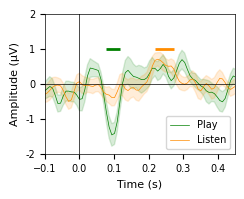

In [17]:
# PLOT
fig = plt.figure(figsize=(1.9,1.4))
ax = fig.add_axes([0,0,1,1])

plot_mean_sem(erp_times, diff_p_erp_ch_mean, diff_p_erp_ch_sem, color = 'green', label = 'Play', linewidth=0.5)
plot_mean_sem(erp_times, diff_l_erp_ch_mean, diff_l_erp_ch_sem, color = 'darkorange', label = 'Listen', linewidth =0.5)


#permutation test to find timepoints of interest
colours = ['green', 'darkorange']
for i,diff_array in enumerate([diff_p_erp_ch, diff_l_erp_ch]):
# for i, diff_array in enumerate([diff_p_erp_ch, diff_l_erp_ch]):
    # run a one‐sample cluster‐based permutation test on the difference
    T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
    diff_array,
    n_permutations=1000,
    tail=0,            # two‐sided by default; use tail=1 or -1 for one‐sided
    out_type="mask"
    )

    sig_idxs = np.where(cluster_p_values < 0.05)[0]  # Get indices of all significant clusters

    for sig_idx in sig_idxs:
        time_slice = clusters[sig_idx][0]  # Get the time slice object
        start, stop, step = time_slice.start, time_slice.stop, time_slice.step or 1
        plt.hlines(1e-6, erp_times[start], erp_times[stop], color = colours[i], linewidth = 2)

        print(erp_times[start], erp_times[stop])

# config_erp_plot(axis_fontsize=None, tick_fontsize=None, linewidth=0.5)
# Add labels, legend, and grid
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (µV)')
# plt.title(f'ERP first and others, {period} training {ch_to_plot}')
plt.hlines(0, -0.5, 0.5, color = 'black')
plt.vlines(0, -6.5e-6, 6e-6, color = 'black')

plt.ticklabel_format(style='plain', axis='y')  # Disable scientific notation
# plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 1e6:.1f}'))  # Convert to µV
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x * 1e6)}'))  # Convert to µV as integer

plt.xlim(-0.1, 0.45)
plt.legend(loc = 'lower right')
plt.ylim(-2e-6, 2e-6)
plt.savefig(f'./figures/erp_diff_{ch_to_plot}.svg', transparent=True)

## $\Delta f-o$, pre vs post

In [32]:
good_listen_subjects, good_motor_subjects,good_error_subjects,musicians,nonmusicians = load_subject_lists_LME()

subjects_playing = good_error_subjects
periods_playing = ['post']
eps_df_playing_post = load_epochs_df(subjects_playing, periods_playing)

eps_df_playing_post['first_evs'] = eps_df_playing_post['first_eps'].apply(lambda x: np.mean(x, axis=0))
eps_df_playing_post['other_evs'] = eps_df_playing_post['other_eps'].apply(lambda x: np.mean(x, axis=0))

eps_df_bytype = eps_df_playing_post.melt(id_vars=['subject', 'period'], value_vars=['first_eps', 'other_eps'], var_name='epochtype', value_name='epochs')
f_df_play= eps_df_bytype.query('epochtype == "first_eps"')
o_df_play = eps_df_bytype.query('epochtype == "other_eps"')
o_df_play = o_df_play.reset_index(drop = True)

IndexError for other_eps in subject 04, period post
IndexError for other_eps in subject 17, period post


In [33]:
#find difference waves
eps_df_playing_post['diff_evs'] = eps_df_playing_post['first_evs'] - eps_df_playing_post['other_evs']

#isolate difference waves over channels
diff_p_erp_ch_post = np.array(eps_df_playing_post['diff_evs'].tolist())[:, ch_idx, :].squeeze()

#mean and sem over subjects for plotting
diff_p_erp_ch_mean_post = np.mean(diff_p_erp_ch_post, axis = 0).flatten()
diff_p_erp_ch_sem_post = sem(diff_p_erp_ch_post, axis = 0).flatten()

In [34]:
diff_prepost_fo = diff_p_erp_ch_post - diff_p_erp_ch
diff_prepost_fo_mean = np.mean(diff_prepost_fo, axis = 0).flatten()
diff_prepost_fo_sem = sem(diff_prepost_fo, axis = 0).flatten()

In [35]:
# FIND SIGNIFICANT CLUSTER TIMEPOINTS for pre post diff
T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
    diff_prepost_fo,
    n_permutations=1000,
    tail=0,            # two‐sided by default; use tail=1 or -1 for one‐sided
    out_type="mask"
    )

sig_idxs = np.where(cluster_p_values < 0.05)[0]
for sig_idx in sig_idxs:
    time_slice = clusters[sig_idx][0]  # Get the time slice object
    start, stop, step = time_slice.start, time_slice.stop, time_slice.step


    print(f'cluster {sig_idx}: p-value = {cluster_p_values[sig_idx]:.4f}, timepoints = {start} to {stop-1}')
    print(f'timepoints: {erp_times[start], erp_times[stop]}')
    

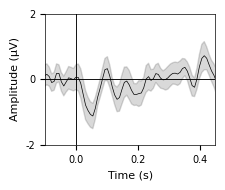

In [56]:

plt.figure(figsize=(2.2,1.7))
ax = fig.add_axes([0,0,1,1]) 
plot_mean_sem(erp_times, diff_prepost_fo_mean, diff_prepost_fo_sem, color = 'black', label = 'diff', linewidth=0.5)

T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
diff_prepost_fo,
n_permutations=1000,
tail=0,            # two‐sided by default; use tail=1 or -1 for one‐sided
out_type="mask"
)

sig_idxs = np.where(cluster_p_values < 0.05)[0]  # Get indices of all significant clusters

for sig_idx in sig_idxs:
    time_slice = clusters[sig_idx][0]  # Get the time slice object
    start, stop, step = time_slice.start, time_slice.stop, time_slice.step or 1
    plt.hlines(1e-6, erp_times[start], erp_times[stop], color = colours[i], linewidth = 2)

plt.xlabel('Time (s)')
plt.ylabel('Amplitude (µV)')
# plt.title(f'ERP first and others, {period} training {ch_to_plot}')
plt.hlines(0, -0.5, 0.5, color = 'black')
plt.vlines(0, -6.5e-6, 6e-6, color = 'black')

plt.xlabel('Time (s)')
plt.ylabel('Amplitude (µV)')
# plt.title(f'ERP first and others, {period} training {ch_to_plot}')
plt.hlines(0, -0.5, 0.5, color = 'black')
plt.vlines(0, -6.5e-6, 6e-6, color = 'black')

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x * 1e6)}'))  # Convert to µV as integer


plt.xlim(-0.1, 0.45)
plt.yticks([-2e-6, 0, 2e-6])
plt.ylim(-2e-6, 2e-6)


plt.savefig(f'./figures/erp_diff_{ch_to_plot}.svg', transparent=True)